In [1]:
!python --version

Python 3.12.2


In [165]:
from pathlib import Path

import pandas as pd
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import MinMaxScaler, FunctionTransformer, PowerTransformer
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.model_selection import train_test_split
from sklearn.utils.validation import check_array, check_is_fitted
from sklearn import set_config

set_config(display='diagram')




In [172]:
DATAPATH = Path("dataset_nuclei_mass.csv")
FEATURES = ['N_Z', 'N', 'Z', 'A', 'BE_per_A', 'DeltaZ', 'DeltaN',
       'DeltaA', 'EvenOddZ', 'EvenOddN']
LABEL = ['MassExcess']

data = pd.read_csv(DATAPATH, usecols=FEATURES + LABEL)
data.head()

,N_Z,N,Z,A,MassExcess,BE_per_A,DeltaZ,DeltaN,DeltaA,EvenOddZ,EvenOddN
0,1,1,0,1,8071.318060,0.00000,0,1,1,0,1
1,-1,0,1,1,7288.971064,0.00000,1,0,1,1,0
2,0,1,1,2,13135.722895,1112.28310,1,1,2,1,1
3,1,2,1,3,14949.810900,2827.26540,1,0,1,1,0
4,-1,1,2,3,14931.218880,2572.68044,0,1,1,0,1


In [146]:

_MAGIC_NUMBERS = [0, 2, 8, 20, 28, 50, 82, 126, 184]

class ClusterSimilarity(BaseEstimator, TransformerMixin):
    def __init__(self, gamma=1.0, random_state=None):
        self.cluster_centers_ = list(zip(_MAGIC_NUMBERS, _MAGIC_NUMBERS))
        self.gamma = gamma
        self.random_state = random_state

    def fit(self, X, y=None):
        # No fitting necessary for this transformer
        return self  # always return self!

    def transform(self, X):
        return rbf_kernel(X, self.cluster_centers_, gamma=self.gamma)

    def get_feature_names_out(self, names=None):
        return [f"boundary_{i}" for i in range(len(self.cluster_centers_))]



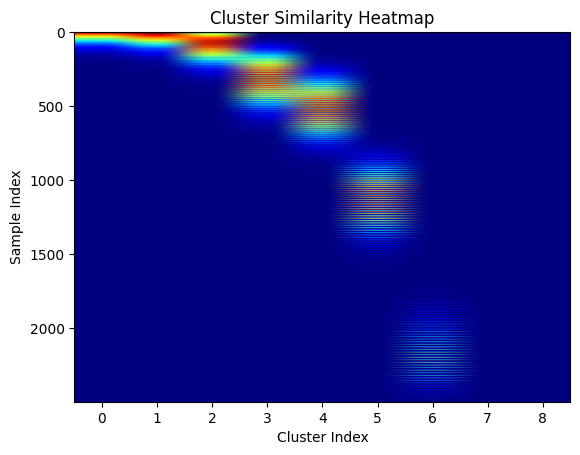

In [207]:
X = data[["N", "Z"]].to_numpy()

cluster_simil = ClusterSimilarity(gamma=0.01)
similarities = cluster_simil.fit_transform(X)

import matplotlib.pyplot as plt

fig, ax = plt.subplots()
ax.imshow(similarities[:2500], aspect='auto', cmap='jet')
ax.set_title("Cluster Similarity Heatmap")
ax.set_xlabel("Cluster Index")
ax.set_ylabel("Sample Index")
plt.show()

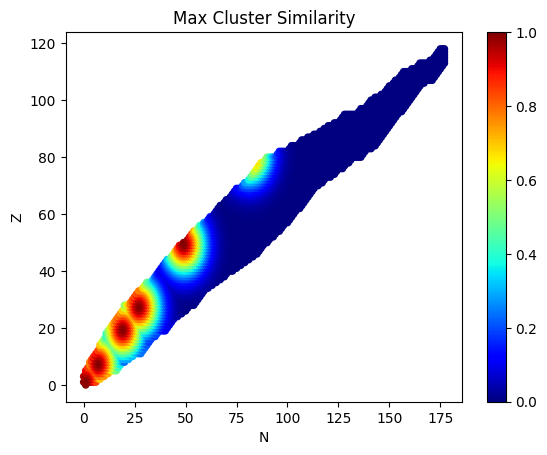

In [206]:
max_cluster_similarity = similarities.max(axis=1)

fig, ax = plt.subplots()
data.plot(
    kind="scatter", 
    x="N", y="Z", 
    ax=ax, 
    c=max_cluster_similarity,
    cmap="jet", colorbar=True,
    legend=True
)
ax.set_title("Max Cluster Similarity")
plt.show()

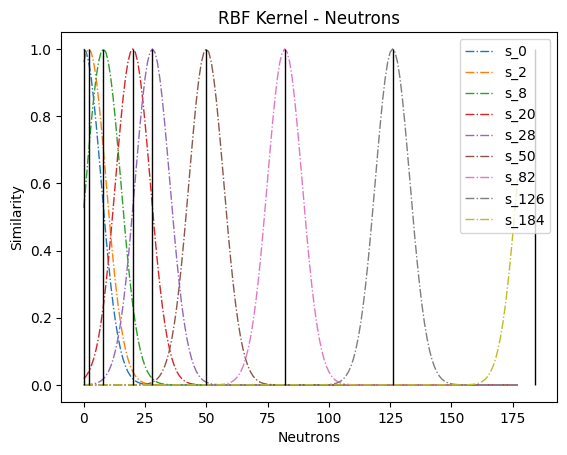

In [92]:
import matplotlib.pyplot as plt


nucleons = np.arange(data["N"].min(), data["N"].max() + 1).reshape(-1, 1)


gamma_value = 0.01
centers = np.array(_MAGIC_NUMBERS).reshape(-1, 1)
rbf_nucleons = rbf_kernel(nucleons, centers, gamma=gamma_value)

#plot figure for neutrons

fig, ax = plt.subplots()

for i in range(rbf_nucleons.shape[1]):

    ordered_indices = np.argsort(nucleons[:, 0])
    ax.plot(nucleons, rbf_nucleons[:, i], label=f"s_{_MAGIC_NUMBERS[i]}", linestyle='-.', lw=1)

ax.vlines(_MAGIC_NUMBERS, ymin=0, ymax=1., colors='black', linestyles='-', lw=1)

ax.set_title("RBF Kernel - Neutrons")
ax.set_xlabel("Neutrons")
ax.set_ylabel("Similarity")
ax.legend()
plt.show()


In [158]:
def surface_term(A):
    return A**(2/3)

def surface_term_pipeline():
    return make_pipeline(
        SimpleImputer(strategy="constant", fill_value=0),
        FunctionTransformer(
            surface_term, 
            feature_names_out=(
                lambda transformer, input_features: ["surface"]
            )
        ),
        MinMaxScaler()
    )

def coulomb_term(X):
    Z = X[:, [0]]
    A = X[:, [1]]
    return Z*(Z-1)/A**(1/3)

def coulomb_term_pipeline():
    return make_pipeline(
        SimpleImputer(strategy="constant", fill_value=0),
        FunctionTransformer(
            coulomb_term, 
            feature_names_out=(
                lambda transformer, input_features: ["coulomb"]
            )
        ),
        MinMaxScaler()
    )

def asymmetry_term(X):
    N = X[:, [0]]
    Z = X[:, [1]]
    return (N-Z)**2/(N+Z)

def asymmetry_term_pipeline():
    return make_pipeline(
        SimpleImputer(strategy="constant", fill_value=0),
        FunctionTransformer(
            asymmetry_term, 
            feature_names_out=(
                lambda transformer, input_features: ["asymmetry"]
            )
        ),
        MinMaxScaler()
    )


In [159]:
num_pipeline = make_pipeline(
    SimpleImputer(strategy="constant", fill_value=0),
    MinMaxScaler()
)    

In [163]:
preprocessing = ColumnTransformer(
    [
        ("num", num_pipeline, ["N", "Z", "A", "DeltaN", "DeltaZ", "DeltaA", "BE_per_A"]),
        ("cat", "passthrough", ["EvenOddZ", "EvenOddN"]),
        ("coef1", surface_term_pipeline(), ["A"]),
        ("coef2", coulomb_term_pipeline(), ["Z", "A"]),
        ("coef3", asymmetry_term_pipeline(), ["N", "Z"]),
        ("sim", ClusterSimilarity(gamma=0.01), ["N", "Z"])

    ],
    remainder="drop",
)


data_prepared = preprocessing.fit_transform(data)
data_prepared_features = preprocessing.get_feature_names_out() 

data_prepared_df = pd.DataFrame(data_prepared, columns=data_prepared_features)
data_prepared_df.head()

,num__N,num__Z,num__A,num__DeltaN,num__DeltaZ,num__DeltaA,num__BE_per_A,cat__EvenOddZ,cat__EvenOddN,coef1__surface,coef2__coulomb,coef3__asymmetry,sim__boundary_0,sim__boundary_1,sim__boundary_2,sim__boundary_3,sim__boundary_4,sim__boundary_5,sim__boundary_6,sim__boundary_7,sim__boundary_8
0,0.005650,0.000000,0.000000,0.034483,0.000000,0.019608,0.204944,0.0,1.0,0.000000,0.000000,0.065211,0.990050,0.951229,0.323033,0.000495,2.686114e-07,5.190718e-22,2.013623e-58,1.559176e-137,3.344885e-293
1,0.000000,0.008475,0.000000,0.000000,0.045455,0.019608,0.204944,1.0,0.0,0.000000,0.000000,0.065211,0.990050,0.951229,0.323033,0.000495,2.686114e-07,5.190718e-22,2.013623e-58,1.559176e-137,3.344885e-293
2,0.005650,0.008475,0.003401,0.034483,0.045455,0.039216,0.305498,1.0,1.0,0.013561,0.000000,0.000000,0.980199,0.980199,0.375311,0.000732,4.655716e-07,1.396944e-21,1.027728e-57,1.918556e-136,1.312931e-291
3,0.011299,0.008475,0.006803,0.000000,0.045455,0.019608,0.460538,1.0,0.0,0.024936,0.000000,0.021737,0.951229,0.990050,0.427415,0.001059,7.909746e-07,3.685061e-21,5.141528e-57,2.314023e-135,5.051458e-290
4,0.005650,0.016949,0.006803,0.034483,0.000000,0.019608,0.437523,0.0,1.0,0.024936,0.000667,0.021737,0.951229,0.990050,0.427415,0.001059,7.909746e-07,3.685061e-21,5.141528e-57,2.314023e-135,5.051458e-290


In [161]:
data.describe()

,N_Z,N,Z,A,MassExcess,BE_per_A,DeltaZ,DeltaN,DeltaA,EvenOddZ,EvenOddN
count,3558.000000,3558.000000,3558.000000,3558.000000,3558.000000,3558.000000,3558.000000,3558.000000,3558.000000,3558.000000,3558.000000
mean,24.474986,82.442945,57.967960,140.410905,-22351.963671,7945.763478,6.989320,9.258010,16.247330,0.499719,0.500843
std,17.861093,43.678883,28.032564,71.192136,57610.095657,740.869722,5.276808,6.978161,10.769734,0.500070,0.500070
min,-8.000000,0.000000,0.000000,1.000000,-91652.843000,-2267.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,10.000000,47.000000,36.000000,84.000000,-64520.999500,7711.765925,3.000000,3.000000,8.000000,0.000000,0.000000
50%,22.000000,81.000000,58.000000,139.000000,-37758.017500,8059.356650,6.000000,8.000000,14.000000,0.000000,1.000000
75%,38.000000,115.000000,80.000000,194.000000,3337.464500,8354.983225,10.000000,14.000000,22.000000,1.000000,1.000000
max,64.000000,177.000000,118.000000,295.000000,201369.000000,8794.555500,22.000000,29.000000,51.000000,1.000000,1.000000


In [162]:
data_prepared_df.describe()

,num__N,num__Z,num__A,num__DeltaN,num__DeltaZ,num__DeltaA,cat__EvenOddZ,cat__EvenOddN,coef1__surface,coef2__coulomb,coef3__asymmetry,sim__boundary_0,sim__boundary_1,sim__boundary_2,sim__boundary_3,sim__boundary_4,sim__boundary_5,sim__boundary_6,sim__boundary_7,sim__boundary_8
count,3558.000000,3558.000000,3558.000000,3558.000000,3558.000000,3558.000000,3558.000000,3558.000000,3558.000000,3558.000000,3558.000000,3.558000e+03,3.558000e+03,3.558000e+03,3.558000e+03,3.558000e+03,3.558000e+03,3.558000e+03,3.558000e+03,3.558000e+03
mean,0.465779,0.491254,0.474187,0.319242,0.317696,0.318575,0.499719,0.500843,0.579478,0.347050,0.326417,1.496963e-02,2.174143e-02,4.230839e-02,6.218166e-02,6.241790e-02,4.792664e-02,1.517721e-02,1.063220e-06,7.861589e-23
std,0.246773,0.237564,0.242150,0.240626,0.239855,0.211171,0.500070,0.500070,0.221972,0.244425,0.267841,9.117538e-02,1.169568e-01,1.633167e-01,1.822433e-01,1.789495e-01,1.509507e-01,6.405256e-02,6.586193e-06,1.947454e-21
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.942511e-197,3.619507e-192,2.579412e-177,1.742253e-149,2.537634e-132,7.427902e-91,2.013623e-58,1.559176e-137,3.344885e-293
25%,0.265537,0.305085,0.282313,0.103448,0.136364,0.156863,0.000000,0.000000,0.419723,0.138437,0.078253,1.566996e-85,3.414197e-82,1.414441e-72,3.014871e-55,4.789036e-45,8.601361e-23,1.575318e-22,9.514918e-63,7.244286e-177
50%,0.457627,0.491525,0.469388,0.275862,0.272727,0.274510,0.000000,1.000000,0.596413,0.309215,0.275193,3.776723e-44,9.428023e-42,5.185108e-35,1.786497e-23,4.368399e-17,3.755667e-09,3.880837e-10,1.095247e-29,9.630964e-116
75%,0.649718,0.677966,0.656463,0.482759,0.454545,0.431373,1.000000,1.000000,0.750601,0.527024,0.537766,2.036762e-16,5.592131e-15,4.343085e-11,2.529351e-05,9.396529e-04,2.357862e-03,2.034684e-04,2.932764e-11,5.033441e-69
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,9.900498e-01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,6.636503e-01,1.221819e-04,7.401642e-20


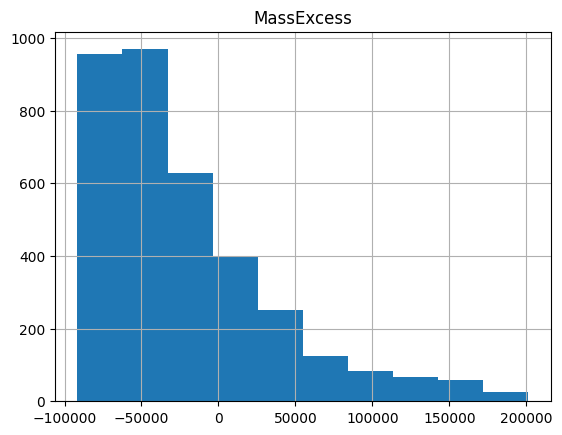

In [164]:
fig, ax = plt.subplots()
data.hist(ax=ax, column="MassExcess")
plt.show()

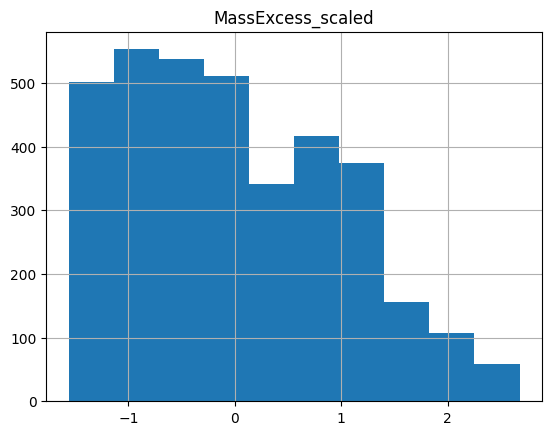

In [168]:

from sklearn.preprocessing import StandardScaler, PowerTransformer

fig, ax = plt.subplots()
scaler = PowerTransformer()
data["MassExcess_scaled"] = scaler.fit_transform(data[["MassExcess"]])
data.hist(ax=ax, column="MassExcess_scaled")
plt.show()

In [219]:
X = data[FEATURES]
y = data[LABEL].to_numpy().ravel()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [220]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

lr_model = TransformedTargetRegressor(LinearRegression(),
                                   transformer=PowerTransformer())

rf_model = TransformedTargetRegressor(RandomForestRegressor(),
                                      transformer=PowerTransformer())

In [231]:
lin_reg = make_pipeline(preprocessing, lr_model)
rf_reg = make_pipeline(preprocessing, rf_model)

In [235]:
from sklearn.metrics import root_mean_squared_error

lin_reg.fit(X_train, y_train)
lr_predictions = lin_reg.predict(X_test)
lr_rmse = root_mean_squared_error(y_test, lr_predictions)
print(f"(lr) Root Mean Squared Error: {lr_rmse:.2f} KeV")

rf_reg.fit(X_train, y_train)
rf_predictions = rf_reg.predict(X_test)
rf_rmse = root_mean_squared_error(y_test, rf_predictions)
print(f"(rf) Root Mean Squared Error: {rf_rmse:.2f} KeV")

(lr) Root Mean Squared Error: 13988.14 KeV
(rf) Root Mean Squared Error: 1578.24 KeV


In [279]:
data_sample = data.iloc[:]

lr_predictions = lin_reg.predict(data_sample)
rf_predictions = rf_reg.predict(data_sample)

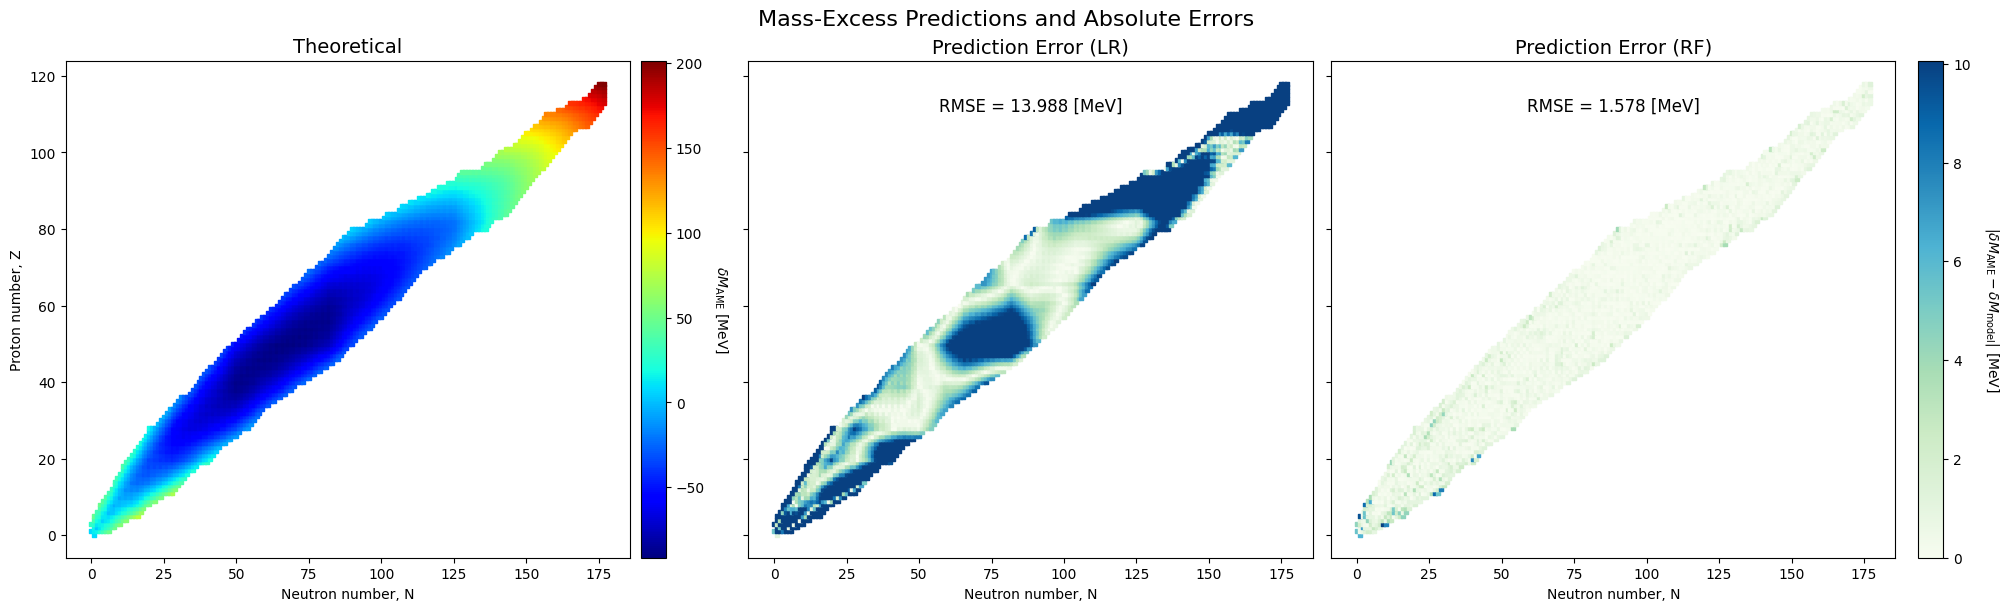

In [286]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# Convert predictions to NumPy arrays if necessary
ground_truth = np.asarray(data_sample["MassExcess"])
lr_predictions = np.asarray(lr_predictions)
rf_predictions = np.asarray(rf_predictions)

# Convert to MeV
ground_truth_mev = ground_truth * 1e-3

# Absolute prediction errors in MeV
lr_error = np.abs(lr_predictions - ground_truth) * 1e-3
rf_error = np.abs(rf_predictions - ground_truth) * 1e-3

# Use the same color limits for both error plots
error_max = min(lr_error.max(), rf_error.max())
error_norm = Normalize(vmin=0, vmax=error_max)

fig, ax = plt.subplots(
    1,
    3,
    figsize=(20, 6),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

# Ground truth
data_sample.plot(
    kind="scatter",
    x="N",
    y="Z",
    ax=ax[0],
    c=ground_truth_mev,
    cmap="jet",
    colorbar=False,
    s=8,
    marker=",",
)

ax[0].set_title("Theoretical", fontsize=14)
ax[0].set_xlabel("Neutron number, N")
ax[0].set_ylabel("Proton number, Z")

# Ground-truth colorbar
ground_truth_scatter = ax[0].collections[0]
ground_truth_cbar = fig.colorbar(
    ground_truth_scatter,
    ax=ax[0],
    pad=0.02,
)

ground_truth_cbar.set_label(
    r"$\delta M_{\mathrm{AME}}\ [\mathrm{MeV}]$",
    rotation=270,
    labelpad=18,
)

# Linear-regression errors
data_sample.plot(
    kind="scatter",
    x="N",
    y="Z",
    ax=ax[1],
    c=lr_error,
    cmap="GnBu",
    colorbar=False,
    norm=error_norm,
    s=8,
    marker=",",
)

ax[1].set_title("Prediction Error (LR)", fontsize=14)
ax[1].set_xlabel("Neutron number, N")
ax[1].set_ylabel("")
ax[1].annotate(
    f"RMSE = {lr_rmse*1e-3:.3f} [MeV]",
    xy=(0.5, 0.9),
    xycoords="axes fraction",
    ha="center",
    fontsize=12,
)

# Random-forest errors
data_sample.plot(
    kind="scatter",
    x="N",
    y="Z",
    ax=ax[2],
    c=rf_error,
    cmap="GnBu",
    colorbar=False,
    norm=error_norm,
    s=8,
    marker=",",
)

ax[2].set_title("Prediction Error (RF)", fontsize=14)
ax[2].set_xlabel("Neutron number, N")
ax[2].set_ylabel("")
ax[2].annotate(
    f"RMSE = {rf_rmse*1e-3:.3f} [MeV]",
    xy=(0.5, 0.9),
    xycoords="axes fraction",
    ha="center",
    fontsize=12,
)

# Shared colorbar for both error plots
error_scatter = ax[2].collections[0]
error_cbar = fig.colorbar(
    error_scatter,
    ax=[ax[1], ax[2]],
    pad=0.02,
)

error_cbar.set_label(
    r"$|\delta M_{\mathrm{AME}}-\delta M_{\mathrm{model}}|\ [\mathrm{MeV}]$",
    rotation=270,
    labelpad=22,
)

# # Improve appearance
# for axis in ax:
#     axis.grid(alpha=0.25, linestyle="--")
#     axis.tick_params(labelsize=10)

fig.suptitle("Mass-Excess Predictions and Absolute Errors", fontsize=16)

plt.show()
